In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

df=pd.read_csv("/content/hour.csv")

In [3]:
df = pd.read_csv("hour.csv")

print(df.shape)
print(df.head())

(17379, 17)
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  


**Dataset Description**


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


**Data Understanding**

In [5]:
df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [8]:
(df["cnt"] == df["casual"] + df["registered"]).all()

np.True_

In [9]:
df["dteday"] = pd.to_datetime(df["dteday"])

df["dteday"].dtype

dtype('<M8[ns]')

In [10]:
df_clean = df.copy()

**Data Cleaning and Feature Engineering**

In [11]:
print("Dataset shape:", df_clean.shape)

Dataset shape: (17379, 17)


In [12]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [13]:
season_map = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

df_clean["season_name"] = df_clean["season"].map(season_map)

In [14]:
weather_map = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow / Fog"
}

df_clean["weather_name"] = df_clean["weathersit"].map(weather_map)

In [15]:
print(df_clean[["season", "season_name",
                "weathersit", "weather_name"]].head())

   season season_name  weathersit           weather_name
0       1      Spring           1  Clear / Partly Cloudy
1       1      Spring           1  Clear / Partly Cloudy
2       1      Spring           1  Clear / Partly Cloudy
3       1      Spring           1  Clear / Partly Cloudy
4       1      Spring           1  Clear / Partly Cloudy


In [16]:
df_clean["dteday"] = pd.to_datetime(df_clean["dteday"])


In [17]:
df_clean["month_name"] = df_clean["dteday"].dt.month_name()
df_clean["day_name"] = df_clean["dteday"].dt.day_name()
df_clean["year"] = df_clean["dteday"].dt.year

print(df_clean[["dteday", "month_name",
                "day_name", "year"]].head())

      dteday month_name  day_name  year
0 2011-01-01    January  Saturday  2011
1 2011-01-01    January  Saturday  2011
2 2011-01-01    January  Saturday  2011
3 2011-01-01    January  Saturday  2011
4 2011-01-01    January  Saturday  2011


In [18]:
def categorize_hour(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df_clean["time_period"] = df_clean["hr"].apply(categorize_hour)

print(df_clean[["hr", "time_period"]].head(10))

   hr time_period
0   0       Night
1   1       Night
2   2       Night
3   3       Night
4   4       Night
5   5     Morning
6   6     Morning
7   7     Morning
8   8     Morning
9   9     Morning


In [19]:
df_clean["temp_celsius"] = df_clean["temp"] * 41
df_clean["feels_like_celsius"] = df_clean["atemp"] * 50
df_clean["humidity_pct"] = df_clean["hum"] * 100
df_clean["windspeed_original_scale"] = df_clean["windspeed"] * 67

print(df_clean[[
    "temp_celsius",
    "feels_like_celsius",
    "humidity_pct",
    "windspeed_original_scale"
]].head())

   temp_celsius  feels_like_celsius  humidity_pct  windspeed_original_scale
0          9.84              14.395          81.0                       0.0
1          9.02              13.635          80.0                       0.0
2          9.02              13.635          80.0                       0.0
3          9.84              14.395          75.0                       0.0
4          9.84              14.395          75.0                       0.0


In [20]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nNew columns:")
print(df_clean.columns.tolist())

Original shape: (17379, 17)
Cleaned shape: (17379, 27)

Missing values:
0

Duplicate rows:
0

New columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'season_name', 'weather_name', 'month_name', 'day_name', 'year', 'time_period', 'temp_celsius', 'feels_like_celsius', 'humidity_pct', 'windspeed_original_scale']


EDA

In [21]:
print("Total bike rentals:", df_clean["cnt"].sum())
print("Average hourly rentals:", df_clean["cnt"].mean())
print("Median hourly rentals:", df_clean["cnt"].median())
print("Maximum hourly rentals:", df_clean["cnt"].max())
print("Minimum hourly rentals:", df_clean["cnt"].min())

Total bike rentals: 3292679
Average hourly rentals: 189.46308763450142
Median hourly rentals: 142.0
Maximum hourly rentals: 977
Minimum hourly rentals: 1


In [22]:
hourly_demand = (
    df_clean.groupby("hr")["cnt"]
    .mean()
    .reset_index()
)

print(hourly_demand)

    hr         cnt
0    0   53.898072
1    1   33.375691
2    2   22.869930
3    3   11.727403
4    4    6.352941
5    5   19.889819
6    6   76.044138
7    7  212.064649
8    8  359.011004
9    9  219.309491
10  10  173.668501
11  11  208.143054
12  12  253.315934
13  13  253.661180
14  14  240.949246
15  15  251.233196
16  16  311.983562
17  17  461.452055
18  18  425.510989
19  19  311.523352
20  20  226.030220
21  21  172.314560
22  22  131.335165
23  23   87.831044


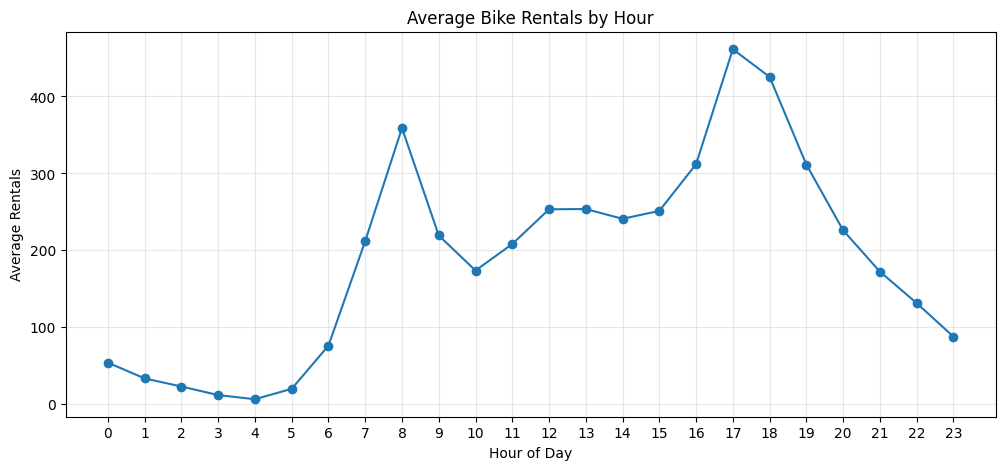

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_demand["hr"],
    hourly_demand["cnt"],
    marker="o"
)
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

In [24]:
season_demand = (
    df_clean.groupby("season_name")["cnt"]
    .mean()
    .reindex(["Spring", "Summer", "Fall", "Winter"])
)

print(season_demand)

season_name
Spring    111.114569
Summer    208.344069
Fall      236.016237
Winter    198.868856
Name: cnt, dtype: float64


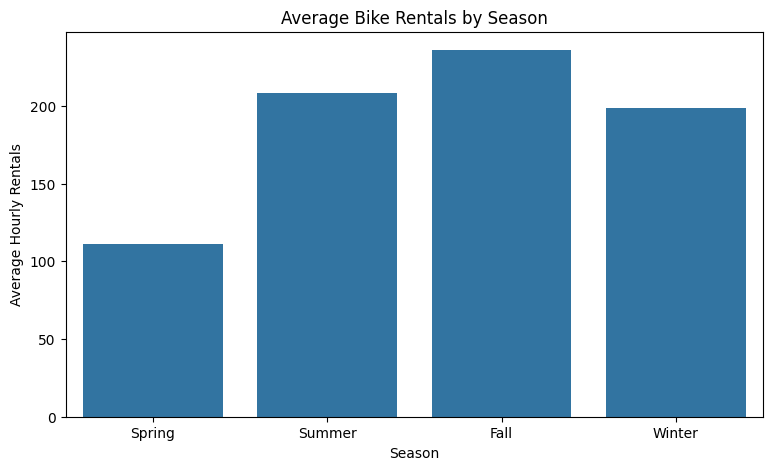

In [25]:
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="season_name",
    y="cnt",
    order=["Spring", "Summer", "Fall", "Winter"],
    errorbar=None
)

plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Hourly Rentals")
plt.show()

In [26]:
working_demand = (
    df_clean.groupby("workingday")["cnt"]
    .mean()
    .reset_index()
)

working_demand["day_type"] = working_demand["workingday"].map({
    0: "Non-working day",
    1: "Working day"
})

print(working_demand)

   workingday         cnt         day_type
0           0  181.405332  Non-working day
1           1  193.207754      Working day


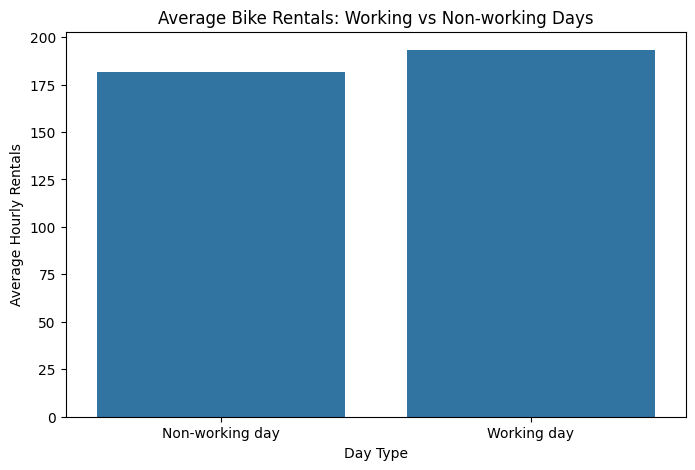

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=working_demand,
    x="day_type",
    y="cnt"
)

plt.title("Average Bike Rentals: Working vs Non-working Days")
plt.xlabel("Day Type")
plt.ylabel("Average Hourly Rentals")
plt.show()

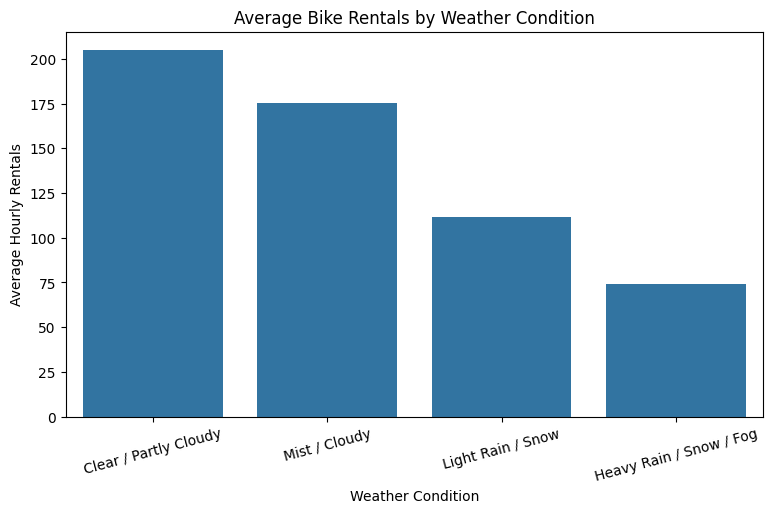

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="weather_name",
    y="cnt",
    order=[
        "Clear / Partly Cloudy",
        "Mist / Cloudy",
        "Light Rain / Snow",
        "Heavy Rain / Snow / Fog"
    ],
    errorbar=None
)

plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Hourly Rentals")
plt.xticks(rotation=15)
plt.show()

   Rider Type  Average Hourly Rentals
0      Casual               35.676218
1  Registered              153.786869


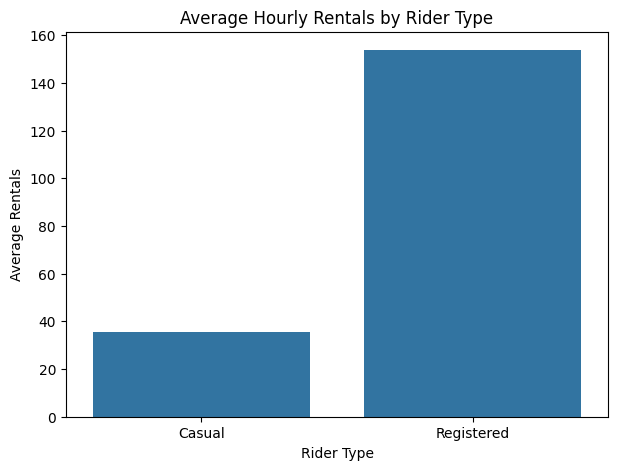

In [29]:
rider_demand = pd.DataFrame({
    "Rider Type": ["Casual", "Registered"],
    "Average Hourly Rentals": [
        df_clean["casual"].mean(),
        df_clean["registered"].mean()
    ]
})

print(rider_demand)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=rider_demand,
    x="Rider Type",
    y="Average Hourly Rentals"
)

plt.title("Average Hourly Rentals by Rider Type")
plt.ylabel("Average Rentals")
plt.show()

**Advanced EDA & Business Insights**

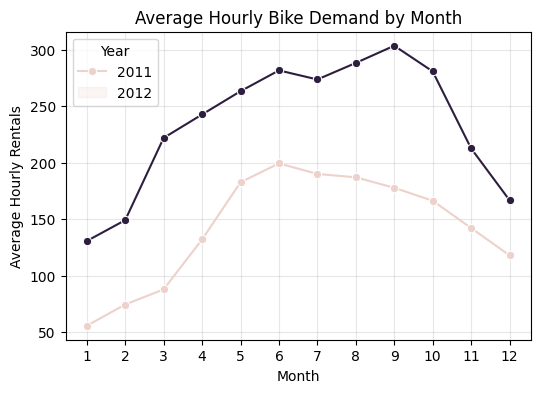

In [30]:
monthly_demand = (
    df_clean.groupby(["year", "mnth"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(6, 4))

sns.lineplot(
    data=monthly_demand,
    x="mnth",
    y="cnt",
    hue="year",
    marker="o"
)

plt.title("Average Hourly Bike Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Hourly Rentals")
plt.xticks(range(1, 13))
plt.legend(title="Year", labels=["2011", "2012"])
plt.grid(alpha=0.3)
plt.show()

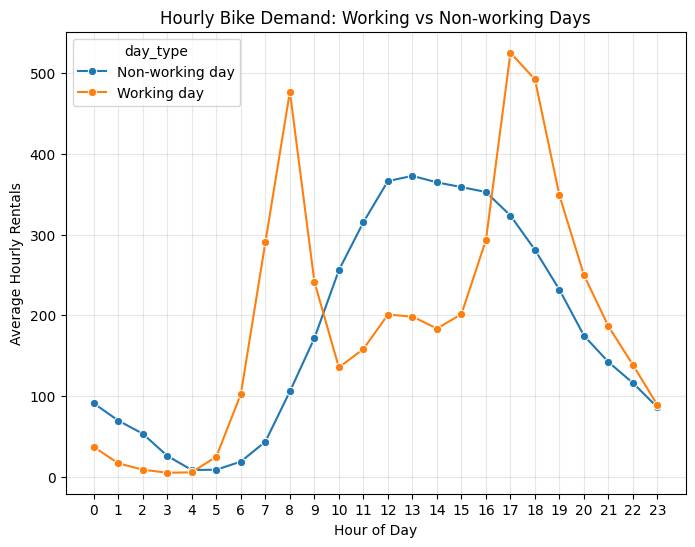

In [31]:
hourly_day_type = (
    df_clean.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

hourly_day_type["day_type"] = hourly_day_type["workingday"].map({
    0: "Non-working day",
    1: "Working day"
})

plt.figure(figsize=(8,6))

sns.lineplot(
    data=hourly_day_type,
    x="hr",
    y="cnt",
    hue="day_type",
    marker="o"
)

plt.title("Hourly Bike Demand: Working vs Non-working Days")
plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly Rentals")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

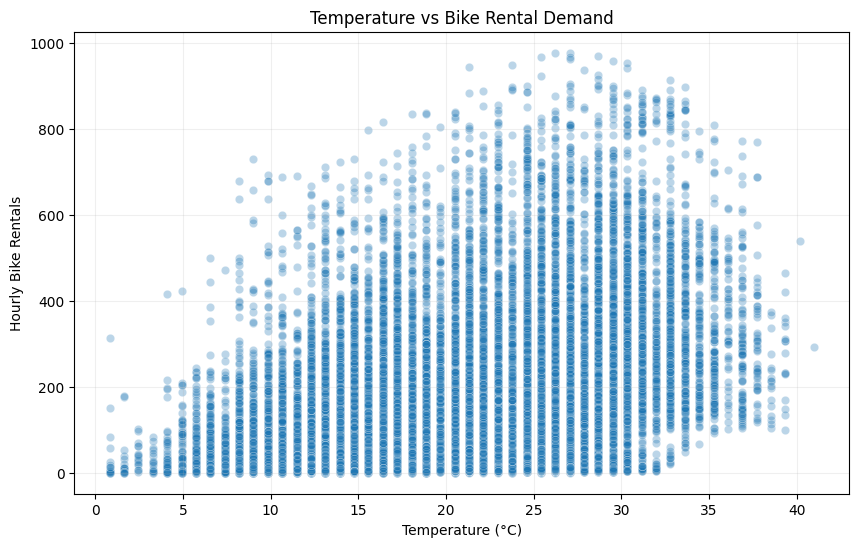

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="temp_celsius",
    y="cnt",
    alpha=0.3
)

plt.title("Temperature vs Bike Rental Demand")
plt.xlabel("Temperature (°C)")
plt.ylabel("Hourly Bike Rentals")
plt.grid(alpha=0.2)
plt.show()

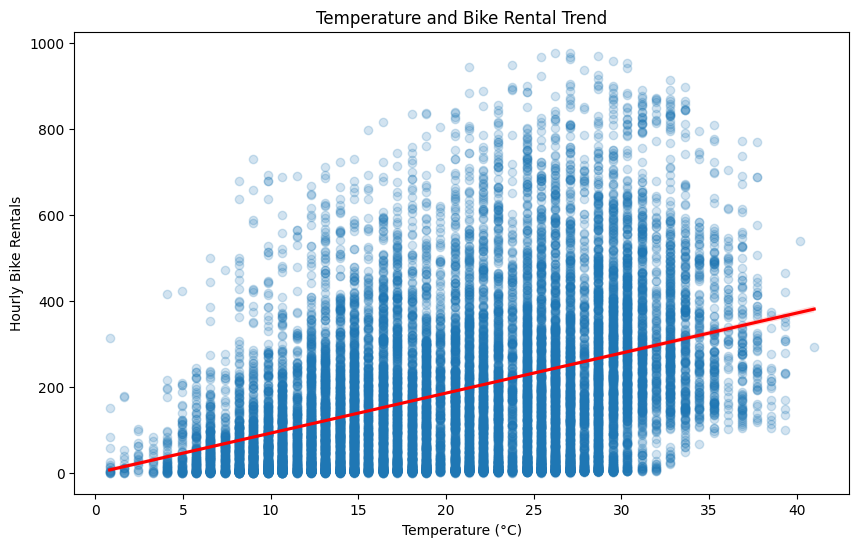

In [33]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x="temp_celsius",
    y="cnt",
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)

plt.title("Temperature and Bike Rental Trend")
plt.xlabel("Temperature (°C)")
plt.ylabel("Hourly Bike Rentals")
plt.show()

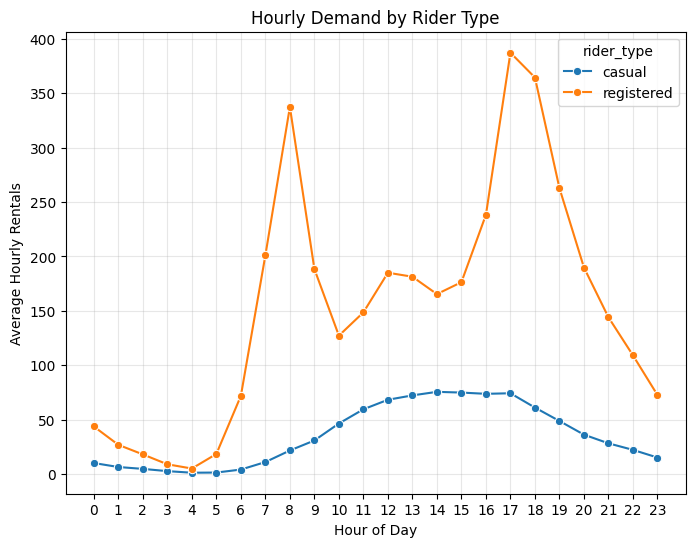

In [34]:
rider_hourly = (
    df_clean.groupby("hr")[["casual", "registered"]]
    .mean()
    .reset_index()
)

rider_hourly_long = rider_hourly.melt(
    id_vars="hr",
    value_vars=["casual", "registered"],
    var_name="rider_type",
    value_name="average_rentals"
)

plt.figure(figsize=(8,6))

sns.lineplot(
    data=rider_hourly_long,
    x="hr",
    y="average_rentals",
    hue="rider_type",
    marker="o"
)

plt.title("Hourly Demand by Rider Type")
plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly Rentals")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

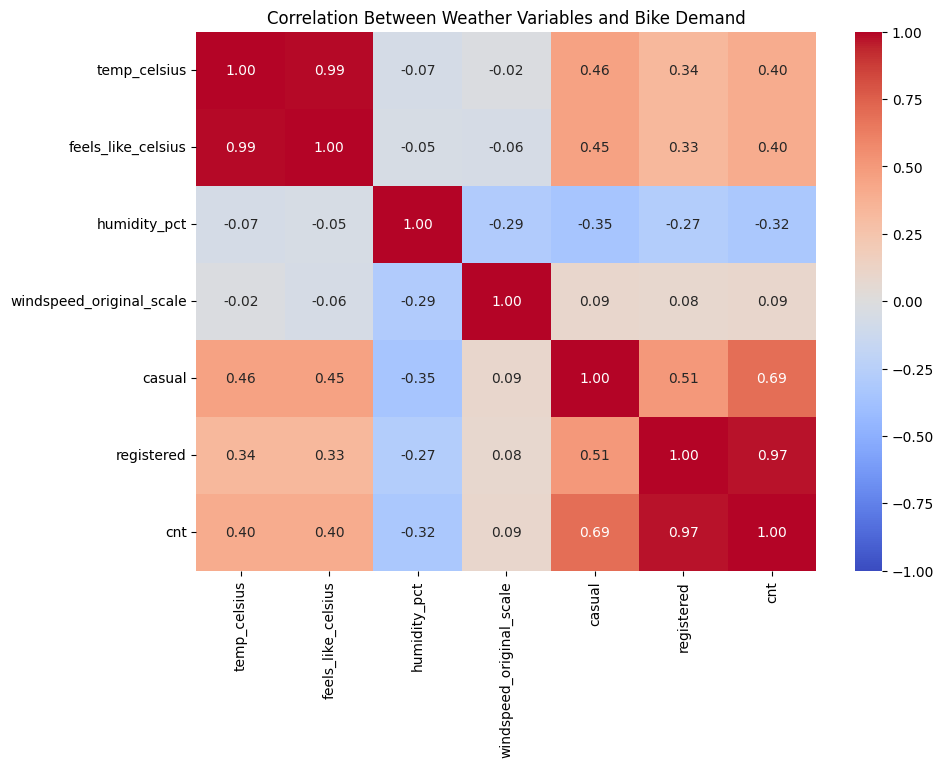

In [35]:
numeric_cols = [
    "temp_celsius",
    "feels_like_celsius",
    "humidity_pct",
    "windspeed_original_scale",
    "casual",
    "registered",
    "cnt"
]

corr_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Weather Variables and Bike Demand")
plt.show()

In [36]:
top_10_hours = (
    df_clean.groupby("hr")["cnt"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print(top_10_hours)

   hr         cnt
0  17  461.452055
1  18  425.510989
2   8  359.011004
3  16  311.983562
4  19  311.523352
5  13  253.661180
6  12  253.315934
7  15  251.233196
8  14  240.949246
9  20  226.030220


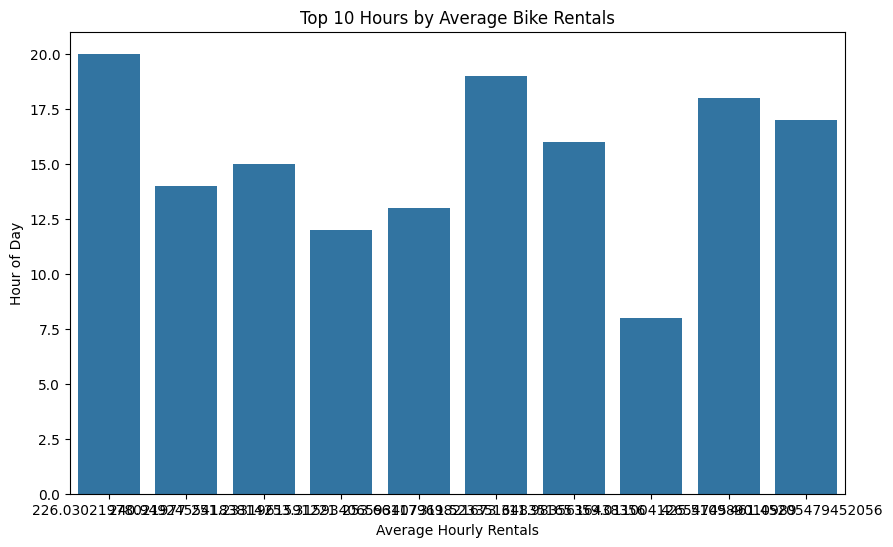

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_hours,
    x="cnt",
    y="hr"
)

plt.title("Top 10 Hours by Average Bike Rentals")
plt.xlabel("Average Hourly Rentals")
plt.ylabel("Hour of Day")
plt.show()

In [38]:
df_clean.to_csv("hour_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [39]:
import os

print(os.path.exists("hour_cleaned.csv"))

True


In [40]:
df_clean.to_excel("hour_cleaned.xlsx", index=False)

## Key Findings

1. **Peak demand:** [Identify the hour or hours with the highest average rentals.]
2. **Seasonal demand:** [Identify the highest- and lowest-demand seasons.]
3. **Monthly trends:** [Summarize the observed monthly pattern and differences between years.]
4. **Weather relationship:** [Describe the strongest observed weather-demand association.]
5. **Rider behavior:** [Explain the difference between casual and registered rider patterns.]
6. **Working-day patterns:** [Describe how hourly demand differs between working and non-working days.]

## Business Recommendations

1. **Bike availability:** Allocate bikes according to observed peak-demand periods.
2. **Seasonal planning:** Adjust fleet availability and maintenance schedules to match seasonal demand.
3. **Rider engagement:** Consider targeted outreach for rider groups with different usage patterns.
4. **Weather-aware operations:** Use weather-demand relationships as one input when planning operations, while accounting for other factors.
5. **Further investigation:** Validate recommendations against additional periods and operational data before implementing major changes.

## Conclusion

This project analyzed the UCI Bike Sharing Dataset to understand hourly bicycle rental demand and its relationship with time, seasons, weather, and rider type.

The analysis used Python, Pandas, NumPy, Matplotlib, and Seaborn to perform data quality checks, feature engineering, exploratory data analysis, and visualization.

The findings help describe demand patterns that a bike-sharing operator could investigate when planning bike availability and operations.

## Limitations

- The dataset covers Washington, D.C., during 2011 and 2012, so the patterns may not represent other cities or current demand.
- The analysis is observational; correlations do not establish causation.
- Weather, calendar variables, and rider behavior may interact, so individual comparisons do not explain every change in demand.
- The dataset contains aggregated rental counts rather than individual trip details and precise pickup/drop-off locations.

## Future Improvements

- Analyze unusual demand spikes and special events.
- Compare weekday and weekend patterns by season.
- Develop a bike-demand forecasting model as an optional extension.
- Validate findings using more recent data from another bike-sharing system.